In [16]:
import fastf1
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor

# 1. Enable FastF1 cache
fastf1.Cache.enable_cache('D:\\Programming\\Python\\AI\\F1 Fantasy\\cache')

year = 2026
gp = 'Belgium'

print(f"Loading practice and race session data for {year} {gp}...")

# Load Practice 2 (often used for long race simulations) and Race sessions
fp2_session = fastf1.get_session(year, gp, 'FP2')
fp2_session.load(telemetry=False, weather=False)

quali_session = fastf1.get_session(year, gp, 'R')
quali_session.load(telemetry=False, weather=False)

race_session = fastf1.get_session(year, gp, 'R')
race_session.load(telemetry=False, weather=False)

# 2. Calculate Long-Run Pace from Practice
# Filter out inaccurate laps, pit laps, and safety car periods (keep clean representative laps)
laps = fp2_session.laps.pick_accurate()
laps = laps[laps['LapTime'].notnull()]

# Convert LapTime timedelta to total seconds for mathematical operations
laps['LapTimeSec'] = laps['LapTime'].dt.total_seconds()

# Group by driver and find their median long-run lap time (ignoring extreme outliers like out-laps)
long_run_pace = laps.groupby('Driver')['LapTimeSec'].median().reset_index()
long_run_pace.rename(columns={'LapTimeSec': 'MedianPracticePace', 'Driver': 'Abbreviation'}, inplace=True)

# 3. Build Training Dataset (Grid Position + Practice Pace -> Finish Position)
results_quali = quali_session.results[['DriverNumber', 'Abbreviation', 'GridPosition']]
results_race = race_session.results[['DriverNumber', 'Position']]

# Merge everything together
training_data = pd.merge(results_quali, results_race, on='DriverNumber')
training_data = pd.merge(training_data, long_run_pace, on='Abbreviation', how='left')

# Drop drivers who didn't finish or have missing metrics
training_data = training_data.dropna(subset=['Position', 'GridPosition', 'MedianPracticePace'])

# Features (X) now include Grid Position AND Practice Pace
X_train = training_data[['GridPosition', 'MedianPracticePace']]
y_train = training_data['Position']

# 4. Train the Model
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)
print("Model successfully trained on Grid Position and Practice Long-Run Pace!")

# 5. Predict on Target/Upcoming Weekend Setup
target_year = 2026
target_gp = 'Hungary' # Change to your target weekend or a test past weekend

print(f"\nLoading target weekend data for {target_year} {target_gp}...")
try:
    target_fp2 = fastf1.get_session(target_year, target_gp, 'FP2')
    target_fp2.load(telemetry=False, weather=False)
    
    target_race = fastf1.get_session(target_year, target_gp, 'R')
    target_race.load(telemetry=False, weather=False)

    # Get target practice pace
    t_laps = target_fp2.laps.pick_accurate()
    t_laps['LapTimeSec'] = t_laps['LapTime'].dt.total_seconds()
    t_pace = t_laps.groupby('Driver')['LapTimeSec'].median().reset_index()
    t_pace.rename(columns={'LapTimeSec': 'MedianPracticePace', 'Driver': 'Abbreviation'}, inplace=True)

    # Get target grid
    target_grid = target_race.results[['DriverNumber', 'Abbreviation', 'GridPosition']].dropna()
    
    # Merge target features
    target_features = pd.merge(target_grid, t_pace, on='Abbreviation', how='left')
    
    # Fill missing practice pace values with the median of the field if a driver missed FP2
    target_features['MedianPracticePace'] = target_features['MedianPracticePace'].fillna(target_features['MedianPracticePace'].median())

    # Predict
    X_target = target_features[['GridPosition', 'MedianPracticePace']]
    target_features['Predicted_Finish'] = model.predict(X_target)

    final_prediction = target_features.sort_values(by='Predicted_Finish')

    print(f"\n--- Predicted Race Result for {target_gp} {target_year} ---")
    for idx, row in enumerate(final_prediction.itertuples(), 1):
        print(f"P{idx}: {row.Abbreviation} (Grid: {int(row.GridPosition)}, FP2 Median: {row.MedianPracticePace:.2f}s), predicted: {row.Predicted_Finish}")

except Exception as e:
    print(f"\nCould not execute target prediction: {e}")

Loading practice and race session data for 2026 Belgium...


core           INFO 	Loading data for Belgian Grand Prix - Practice 2 [v3.8.3]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 22 drivers: ['1', '3', '5', '6', '10', '11', '12', '14', '16', '18', '23', '27', '30', '31', '41', '43', '44', '55', '63', '77', '81', '87']
core           INFO 	Loading data for Belgian Grand Prix - Race [v3.8.3]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            

Model successfully trained on Grid Position and Practice Long-Run Pace!

Loading target weekend data for 2026 Hungary...


req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
core        WARNING 	No lap data for driver 18
core        WARNING 	Failed to perform lap accuracy check - all laps marked as inaccurate (driver 18)
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 22 drivers: ['1', '3', '5', '6', '10', '11', '12', '14', '16', '18', '23', '27', '30', '31', '41', '43', '44', '55', '63', '77', '81', '87']
core           INFO 	Loading data for Hungarian Grand Prix - Race [v3.8.3]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core 


--- Predicted Race Result for Hungary 2026 ---
P1: NOR (Grid: 1, FP2 Median: 84.97s), predicted: 2.92
P2: LEC (Grid: 2, FP2 Median: 86.15s), predicted: 3.29
P3: HAM (Grid: 5, FP2 Median: 84.98s), predicted: 4.58
P4: RUS (Grid: 6, FP2 Median: 84.73s), predicted: 5.16
P5: VER (Grid: 4, FP2 Median: 84.14s), predicted: 5.68
P6: PIA (Grid: 3, FP2 Median: 85.68s), predicted: 6.83
P7: ANT (Grid: 7, FP2 Median: 84.07s), predicted: 6.94
P8: HAD (Grid: 8, FP2 Median: 88.70s), predicted: 7.57
P9: COL (Grid: 13, FP2 Median: 105.32s), predicted: 8.47
P10: LIN (Grid: 9, FP2 Median: 85.94s), predicted: 8.66
P11: LAW (Grid: 11, FP2 Median: 85.77s), predicted: 8.92
P12: HUL (Grid: 10, FP2 Median: 85.37s), predicted: 8.99
P13: GAS (Grid: 12, FP2 Median: 86.58s), predicted: 9.38
P14: BOT (Grid: 21, FP2 Median: 88.09s), predicted: 10.09
P15: PER (Grid: 22, FP2 Median: 87.81s), predicted: 10.47
P16: BOR (Grid: 14, FP2 Median: 85.61s), predicted: 10.66
P17: OCO (Grid: 15, FP2 Median: 86.49s), predicted: 11

C:\Users\nanub\AppData\Local\Temp\ipykernel_17744\1269510206.py:70: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  t_laps['LapTimeSec'] = t_laps['LapTime'].dt.total_seconds()


In [17]:
import fastf1
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor

# 1. Enable FastF1 cache
fastf1.Cache.enable_cache('D:\\Programming\\Python\\AI\\F1 Fantasy\\cache')

# Define multiple rounds to use as training data (Year, Grand Prix Name)
training_rounds = [
    (2026, 'Belgium'),
    (2026, 'Ausria'),
    (2026, 'Silverstone'),
    (2026, 'Barcelona'),
    (2026, 'Monaco')
]

master_training_data = []

print("Aggregating data across multiple rounds...")

for year, gp in training_rounds:
    try:
        print(f"Processing {year} {gp}...")
        
        # Load FP2 (long runs) and Race sessions
        fp2 = fastf1.get_session(year, gp, 'FP2')
        fp2.load(telemetry=False, weather=False)
        
        race = fastf1.get_session(year, gp, 'R')
        race.load(telemetry=False, weather=False)
        
        # Calculate practice pace
        laps = fp2.laps.pick_accurate()
        laps = laps[laps['LapTime'].notnull()]
        laps['LapTimeSec'] = laps['LapTime'].dt.total_seconds()
        
        # Median lap time per driver
        driver_pace = laps.groupby('Driver')['LapTimeSec'].median().reset_index()
        driver_pace.rename(columns={'LapTimeSec': 'MedianPace', 'Driver': 'Abbreviation'}, inplace=True)
        
        # NORMALIZE: Convert raw time to a Delta against the fastest driver in that session
        fastest_time = driver_pace['MedianPace'].min()
        driver_pace['PaceDelta'] = driver_pace['MedianPace'] - fastest_time
        
        # Get grid and final results
        results = race.results[['DriverNumber', 'Abbreviation', 'GridPosition', 'Position']].dropna(subset=['Position'])
        
        # Merge pace delta with race results
        round_data = pd.merge(results, driver_pace[['Abbreviation', 'PaceDelta']], on='Abbreviation', how='left')
        
        # Append to master list
        master_training_data.append(round_data)
        
    except Exception as e:
        print(f"Skipping {year} {gp} due to error: {e}")

# Combine all rounds into one large training dataframe
if len(master_training_data) > 0:
    full_train_df = pd.concat(master_training_data, ignore_index=True)
    full_train_df = full_train_df.dropna(subset=['GridPosition', 'PaceDelta', 'Position'])

    # Features (X) and Target (y)
    X_train = full_train_df[['GridPosition', 'PaceDelta']]
    y_train = full_train_df['Position']

    # 2. Train the Model on Multi-Round Data
    model = RandomForestRegressor(n_estimators=150, random_state=42)
    model.fit(X_train, y_train)
    print(f"\nModel successfully trained on {len(full_train_df)} driver-race data points across multiple rounds!")

    # 3. Predict an Upcoming or Target Race
    target_year = 2026
    target_gp = 'Hungary' # Change to your target race

    print(f"\nLoading target weekend: {target_year} {target_gp}...")
    target_fp2 = fastf1.get_session(target_year, target_gp, 'FP2')
    target_fp2.load(telemetry=False, weather=False)
    
    target_race = fastf1.get_session(target_year, target_gp, 'R')
    target_race.load(telemetry=False, weather=False)

    # Calculate target pace delta
    t_laps = target_fp2.laps.pick_accurate()
    t_laps['LapTimeSec'] = t_laps['LapTime'].dt.total_seconds()
    t_pace = t_laps.groupby('Driver')['LapTimeSec'].median().reset_index()
    t_pace.rename(columns={'LapTimeSec': 'MedianPace', 'Driver': 'Abbreviation'}, inplace=True)
    t_fastest = t_pace['MedianPace'].min()
    t_pace['PaceDelta'] = t_pace['MedianPace'] - t_fastest

    # Target grid
    t_grid = target_race.results[['DriverNumber', 'Abbreviation', 'GridPosition']].dropna()
    
    # Merge and handle missing values
    target_features = pd.merge(t_grid, t_pace[['Abbreviation', 'PaceDelta']], on='Abbreviation', how='left')
    target_features['PaceDelta'] = target_features['PaceDelta'].fillna(target_features['PaceDelta'].median())

    # Predict final positions
    X_target = target_features[['GridPosition', 'PaceDelta']]
    target_features['Predicted_Finish'] = model.predict(X_target)

    final_prediction = target_features.sort_values(by='Predicted_Finish')

    print(f"\n--- Multi-Round Model Prediction for {target_gp} {target_year} ---")
    for idx, row in enumerate(final_prediction.itertuples(), 1):
        print(f"P{idx}: {row.Abbreviation} (Grid: {int(row.GridPosition)}, Pace Delta: +{row.PaceDelta:.3f}s)")

else:
    print("No training data collected. Check your round list.")

core           INFO 	Loading data for Belgian Grand Prix - Practice 2 [v3.8.3]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...


Aggregating data across multiple rounds...
Processing 2026 Belgium...


req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 22 drivers: ['1', '3', '5', '6', '10', '11', '12', '14', '16', '18', '23', '27', '30', '31', '41', '43', '44', '55', '63', '77', '81', '87']
core           INFO 	Loading data for Belgian Grand Prix - Race [v3.8.3]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
core        WARNING 	Fixed incorrect tyre stint information for driver '12'
core        WARNING 	Driver 12 completed the race distance 00:00.045000 before the recorded end of the session.
req            INFO 	Using 

Processing 2026 Ausria...


req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 22 drivers: ['1', '3', '5', '6', '10', '11', '12', '14', '16', '18', '23', '27', '30', '31', '41', '43', '44', '55', '63', '77', '81', '87']
events      WARNING 	Correcting user input 'Ausria' to 'Austrian Grand Prix'
core           INFO 	Loading data for Austrian Grand Prix - Race [v3.8.3]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req          

...

req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 22 drivers: ['1', '3', '5', '6', '10', '11', '12', '14', '16', '18', '23', '27', '30', '31', '41', '43', '44', '55', '63', '77', '81', '87']
core           INFO 	Loading data for Monaco Grand Prix - Race [v3.8.3]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using 


Model successfully trained on 87 driver-race data points across multiple rounds!

Loading target weekend: 2026 Hungary...


core        WARNING 	No lap data for driver 18
core        WARNING 	Failed to perform lap accuracy check - all laps marked as inaccurate (driver 18)
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 22 drivers: ['1', '3', '5', '6', '10', '11', '12', '14', '16', '18', '23', '27', '30', '31', '41', '43', '44', '55', '63', '77', '81', '87']
core           INFO 	Loading data for Hungarian Grand Prix - Race [v3.8.3]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
core        WARNING 	Fixed incorrect tyre stint information for 


--- Multi-Round Model Prediction for Hungary 2026 ---
P1: VER (Grid: 4, Pace Delta: +0.076s)
P2: HAM (Grid: 5, Pace Delta: +0.916s)
P3: RUS (Grid: 6, Pace Delta: +0.668s)
P4: ANT (Grid: 7, Pace Delta: +0.000s)
P5: NOR (Grid: 1, Pace Delta: +0.903s)
P6: HAD (Grid: 8, Pace Delta: +4.635s)
P7: PIA (Grid: 3, Pace Delta: +1.618s)
P8: HUL (Grid: 10, Pace Delta: +1.308s)
P9: LIN (Grid: 9, Pace Delta: +1.870s)
P10: LAW (Grid: 11, Pace Delta: +1.704s)
P11: BOR (Grid: 14, Pace Delta: +1.541s)
P12: GAS (Grid: 12, Pace Delta: +2.511s)
P13: COL (Grid: 13, Pace Delta: +21.251s)
P14: OCO (Grid: 15, Pace Delta: +2.424s)
P15: BEA (Grid: 17, Pace Delta: +2.502s)
P16: LEC (Grid: 2, Pace Delta: +2.087s)
P17: ALO (Grid: 16, Pace Delta: +5.094s)
P18: SAI (Grid: 18, Pace Delta: +3.370s)
P19: BOT (Grid: 21, Pace Delta: +4.022s)
P20: ALB (Grid: 19, Pace Delta: +3.668s)
P21: PER (Grid: 22, Pace Delta: +3.743s)
P22: STR (Grid: 20, Pace Delta: +2.087s)


C:\Users\nanub\AppData\Local\Temp\ipykernel_17744\2748239605.py:85: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  t_laps['LapTimeSec'] = t_laps['LapTime'].dt.total_seconds()


In [1]:
import fastf1
import pandas as pd
import numpy as np
from scipy.stats import linregress

# 1. Enable FastF1 cache
fastf1.Cache.enable_cache('D:\\Programming\\Python\\AI\\F1 Fantasy\\cache')

In [2]:
round = "hungary"

session = fastf1.get_session(2026, round, "FP2")
session.load(telemetry=False)

core           INFO 	Loading data for Hungarian Grand Prix - Practice 2 [v3.8.3]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
core        WARNING 	No lap data for driver 18
core        WARNING 	Failed to perform lap accuracy check - all laps marked as inaccurate (driver 18)
req            INFO 	Using cached data for weather_data
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 22 drivers: ['1', '3', '5', '6', '10', '11', '12', '14', '16', '18', '23', '27', '30', '31', '41', '43', '44', '55', '63', '77', '81', '87']


In [3]:
longRuns = []

for driver in session.drivers:
    driverInfo = session.get_driver(driver)

    laps = session.laps.pick_drivers(driver)
    actual_laps = laps.pick_accurate().pick_wo_box()

    # group by both stint and compound
    grouped_stints = actual_laps.groupby(['Stint', 'Compound'])

    for (stint, compound), group in grouped_stints:
        clean_laps = group.pick_quicklaps(threshold=1.045).copy()

        # long runs must be at least 5 laps long
        if len(clean_laps) >= 5:
            # Normalize for fuel load (burns about .035s per lap)
            FUEL_EFFECT_PER_LAP = 0.035
            clean_laps["LapInStint"] = clean_laps["LapNumber"] - clean_laps["LapNumber"].iloc[0]
            clean_laps["NormalizedLapTime"] = (
                clean_laps["LapTime"].dt.total_seconds() + clean_laps["LapInStint"] * FUEL_EFFECT_PER_LAP
            )

            avg_time = clean_laps['NormalizedLapTime'].mean()

            # Find best fit line to estimate tire deg and base pace
            result = linregress(
                clean_laps["TyreLife"],
                clean_laps["NormalizedLapTime"]
            )
            
            degradation = result.slope
            base_pace = result.intercept
            r2 = result.rvalue ** 2

            # Calculate confidence score
            confidence = r2 * np.minimum(len(clean_laps) / 12, 1)

            longRuns.append({
                'Driver': driverInfo['Abbreviation'],
                'Compound': compound,
                'Pace': avg_time,
                'PaceStd': clean_laps["NormalizedLapTime"].std(),
                'Laps': len(clean_laps),
                'Start Tyre Life': clean_laps["TyreLife"].iloc[0],
                'End Tyre Life': clean_laps["TyreLife"].iloc[-1],
                'Estimated Tyre Deg': degradation,
                'Estimated Base Pace': base_pace,
                'Stint': stint,
                'R2': r2,
                'Confidence': confidence,
                'DegStdErr': result.stderr
            })

df_longRuns = pd.DataFrame(longRuns)
df_longRuns = df_longRuns.sort_values(by='Pace', ascending=True)
df_longRuns

,Driver,Compound,Pace,PaceStd,Laps,Start Tyre Life,End Tyre Life,Estimated Tyre Deg,Estimated Base Pace,Stint,R2,Confidence,DegStdErr
6,ANT,SOFT,84.334857,0.816281,7,6.0,13.0,0.264562,81.878214,7.0,0.690294,0.402671,0.079250
2,VER,SOFT,84.451833,0.823729,6,5.0,10.0,0.275857,82.382905,4.0,0.392525,0.196263,0.171587
0,NOR,MEDIUM,85.017727,0.816156,11,8.0,18.0,0.220291,82.153945,3.0,0.801382,0.734600,0.036556
16,RUS,MEDIUM,85.145750,0.987279,12,10.0,22.0,0.150357,82.802692,4.0,0.326641,0.326641,0.068267
1,VER,MEDIUM,85.232857,1.373084,7,7.0,13.0,0.473321,80.499643,3.0,0.554530,0.323476,0.189722
8,LEC,SOFT,85.328444,1.325783,9,8.0,16.0,0.268700,82.104044,4.0,0.308072,0.231054,0.152203
14,HAM,MEDIUM,85.343500,1.062847,6,11.0,16.0,-0.043800,85.934800,4.0,0.005944,0.002972,0.283212
10,HUL,SOFT,85.502000,0.160472,7,9.0,15.0,-0.034607,85.917286,5.0,0.217039,0.126606,0.029396
18,PIA,MEDIUM,85.622000,0.380798,8,12.0,19.0,0.131762,83.579690,5.0,0.718360,0.478907,0.033681
11,LAW,HARD,85.854250,0.890492,8,11.0,20.0,0.172497,83.202102,5.0,0.396009,0.264006,0.086970


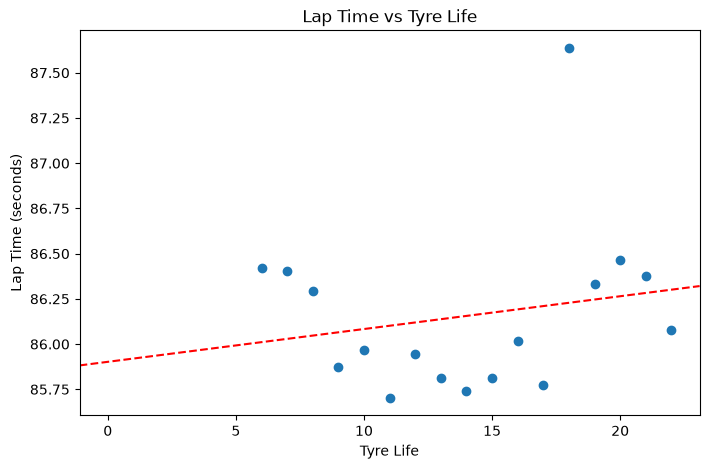

In [21]:
import matplotlib.pyplot as plt

laps = session.laps.pick_drivers("ant")
actual_laps = laps.pick_accurate().pick_wo_box()

stint = actual_laps.loc[actual_laps['Stint'] == 4].pick_quicklaps(1.05).copy()
stint['LapTimeSeconds'] = stint['LapTime'].dt.total_seconds()
stint[['LapTimeSeconds', 'TyreLife']]

x = np.array(stint['TyreLife'])
y = np.array(stint['LapTimeSeconds'])

m, b = np.polyfit(x, y, 1)

plt.figure(figsize=(8, 5))

plt.scatter(
    stint["TyreLife"],
    stint["LapTimeSeconds"]
)
plt.axline(xy1=(0, b), slope=m, color="red", linestyle="--", label=f"Best Fit: y={m:.2f}x+{b:.2f}")

plt.xlabel("Tyre Life")
plt.ylabel("Lap Time (seconds)")
plt.title("Lap Time vs Tyre Life")

plt.show()

In [22]:
from scipy.stats import linregress

result = linregress(
    stint["TyreLife"],
    stint["LapTimeSeconds"]
)

degradation = result.slope
base_pace = result.intercept
r2 = result.rvalue ** 2
r2

np.float64(0.03874375727933984)

In [71]:
events = fastf1.get_events_remaining()
nextRound = events.iloc[0].RoundNumber

# Manually making it hungary for now
nextRound = 11

for round in range(1, nextRound):
    session = fastf1.get_session(2026, round, "R")
    session.load(telemetry=False)

    laps = session.laps.copy()
    laps["LapInStint"] = (
        laps.groupby(["Driver", "Stint"]).cumcount()
    )
    quick_laps = laps.pick_accurate().pick_quicklaps().copy()
    quick_laps["LapTimeSeconds"] = quick_laps["LapTime"].dt.total_seconds()

    quick_laps.to_csv(f'data/races/{session.event.EventDate.year}_{session.event.EventName}.csv', index=False)

core           INFO 	Loading data for Australian Grand Prix - Race [v3.8.3]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
core        WARNING 	Failed to perform lap accuracy check - all laps marked as inaccurate (driver 81)
core        WARNING 	Failed to perform lap accuracy check - all laps marked as inaccurate (driver 27)
req            INFO 	Using cached data for weather_data
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 22 drivers: ['63', '12', '16', '44', '1', '3', '87', '41', '5', '10', '31', '23', '30', '43',

In [2]:
session = pd.read_csv(f'data/races/2026_Belgian Grand Prix.csv')
laps = fastf1.core.Laps(session)

FUEL_EFFECT_PER_LAP = 0.035

laps["LapInStint"] = (
    laps.groupby(["Driver", "Stint"]).cumcount()
)
laps["NormalizedLapTime"] = (
    laps["LapTimeSeconds"] + laps["LapInStint"] * FUEL_EFFECT_PER_LAP
)
laps

,Time,Driver,DriverNumber,LapTime,LapNumber,Stint,PitOutTime,PitInTime,Sector1Time,Sector2Time,...,LapStartDate,TrackStatus,Position,Deleted,DeletedReason,FastF1Generated,IsAccurate,LapInStint,LapTimeSeconds,NormalizedLapTime
0,0 days 01:08:01.325000,ANT,12,0 days 00:01:51.638000,5.0,1.0,NaN,NaN,0 days 00:00:31.740000,0 days 00:00:49.916000,...,NaN,1,1.0,False,NaN,False,True,0,111.638,111.638
1,0 days 01:09:52.640000,ANT,12,0 days 00:01:51.315000,6.0,1.0,NaN,NaN,0 days 00:00:31.424000,0 days 00:00:49.856000,...,NaN,1,1.0,False,NaN,False,True,1,111.315,111.350
2,0 days 01:11:43.597000,ANT,12,0 days 00:01:50.957000,7.0,1.0,NaN,NaN,0 days 00:00:31.459000,0 days 00:00:49.581000,...,NaN,1,1.0,False,NaN,False,True,2,110.957,111.027
3,0 days 01:13:34.583000,ANT,12,0 days 00:01:50.986000,8.0,1.0,NaN,NaN,0 days 00:00:31.546000,0 days 00:00:49.565000,...,NaN,12,1.0,False,NaN,False,True,3,110.986,111.091
4,0 days 01:15:25.408000,ANT,12,0 days 00:01:50.825000,9.0,1.0,NaN,NaN,0 days 00:00:31.549000,0 days 00:00:49.468000,...,NaN,1,1.0,False,NaN,False,True,4,110.825,110.965
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
681,0 days 01:12:05.778000,PER,11,0 days 00:01:54.992000,7.0,2.0,NaN,NaN,0 days 00:00:32.503000,0 days 00:00:52.203000,...,NaN,1,18.0,False,NaN,False,True,1,114.992,115.027
682,0 days 01:13:59.753000,PER,11,0 days 00:01:53.975000,8.0,2.0,NaN,NaN,0 days 00:00:32.158000,0 days 00:00:51.621000,...,NaN,12,18.0,False,NaN,False,True,2,113.975,114.045
683,0 days 01:15:53.230000,PER,11,0 days 00:01:53.477000,9.0,2.0,NaN,NaN,0 days 00:00:32.132000,0 days 00:00:51.346000,...,NaN,1,18.0,True,TRACK LIMITS AT TURN 4 LAP 9,False,True,3,113.477,113.582
684,0 days 01:17:46.750000,PER,11,0 days 00:01:53.520000,10.0,2.0,NaN,NaN,0 days 00:00:32.038000,0 days 00:00:51.237000,...,NaN,1,18.0,False,NaN,False,True,4,113.520,113.660


In [30]:
from pathlib import Path
import pandas as pd
import numpy as np
import fastf1

FUEL_EFFECT_PER_LAP = 0.035

all_laps = []

dir_path = Path('data/races/')

for raceFile in dir_path.iterdir():
    if raceFile.is_file():
        raceData = pd.read_csv(raceFile)
        laps = fastf1.core.Laps(raceData)
        laps["Event"] = raceFile.stem
        all_laps.append(laps)

laps = pd.concat(all_laps, ignore_index=True)

laps["LapInStint"] = (
    laps.groupby(["Event", "Driver", "Stint"]).cumcount()
)

laps["FuelCorrectedLapTime"] = (
    laps["LapTimeSeconds"] + laps["LapInStint"] * FUEL_EFFECT_PER_LAP
)

eventCompoundReference = (
    laps
    .groupby(["Event", "Compound"])["FuelCorrectedLapTime"]
    .median()
    .rename("EventCompoundReference")
    .reset_index()
)

laps = laps.merge(eventCompoundReference, on=["Event", "Compound"], how="left")
laps["RelativePace"] = laps["FuelCorrectedLapTime"] - laps["EventCompoundReference"]

print(laps.shape)
print(laps[["Event"]].drop_duplicates().shape[0])
print(laps["Compound"].value_counts())

laps.head(20)

(8180, 37)
10
Compound
HARD      4222
MEDIUM    3075
SOFT       883
Name: count, dtype: int64


,Time,Driver,DriverNumber,LapTime,LapNumber,Stint,PitOutTime,PitInTime,Sector1Time,Sector2Time,...,Deleted,DeletedReason,FastF1Generated,IsAccurate,LapInStint,LapTimeSeconds,Event,FuelCorrectedLapTime,EventCompoundReference,RelativePace
0,0 days 01:05:23.781000,NOR,1,0 days 00:01:27.344000,2.0,1.0,NaN,NaN,0 days 00:00:31.074000,0 days 00:00:18.116000,...,False,NaN,False,True,0,87.344,2026_Australian Grand Prix,87.344,85.369,1.975
1,0 days 01:06:50.644000,NOR,1,0 days 00:01:26.863000,3.0,1.0,NaN,NaN,0 days 00:00:30.541000,0 days 00:00:18.252000,...,False,NaN,False,True,1,86.863,2026_Australian Grand Prix,86.898,85.369,1.529
2,0 days 01:08:16.501000,NOR,1,0 days 00:01:25.857000,4.0,1.0,NaN,NaN,0 days 00:00:30.190000,0 days 00:00:18.193000,...,False,NaN,False,True,2,85.857,2026_Australian Grand Prix,85.927,85.369,0.558
3,0 days 01:09:42.074000,NOR,1,0 days 00:01:25.573000,5.0,1.0,NaN,NaN,0 days 00:00:29.930000,0 days 00:00:17.868000,...,False,NaN,False,True,3,85.573,2026_Australian Grand Prix,85.678,85.369,0.309
4,0 days 01:11:07.110000,NOR,1,0 days 00:01:25.036000,6.0,1.0,NaN,NaN,0 days 00:00:30.025000,0 days 00:00:17.829000,...,False,NaN,False,True,4,85.036,2026_Australian Grand Prix,85.176,85.369,-0.193
5,0 days 01:12:32.088000,NOR,1,0 days 00:01:24.978000,7.0,1.0,NaN,NaN,0 days 00:00:30.067000,0 days 00:00:17.764000,...,False,NaN,False,True,5,84.978,2026_Australian Grand Prix,85.153,85.369,-0.216
6,0 days 01:13:57.387000,NOR,1,0 days 00:01:25.299000,8.0,1.0,NaN,NaN,0 days 00:00:30.191000,0 days 00:00:17.970000,...,False,NaN,False,True,6,85.299,2026_Australian Grand Prix,85.509,85.369,0.140
7,0 days 01:15:23.026000,NOR,1,0 days 00:01:25.639000,9.0,1.0,NaN,NaN,0 days 00:00:30.135000,0 days 00:00:17.770000,...,False,NaN,False,True,7,85.639,2026_Australian Grand Prix,85.884,85.369,0.515
8,0 days 01:16:48.321000,NOR,1,0 days 00:01:25.295000,10.0,1.0,NaN,NaN,0 days 00:00:30.117000,0 days 00:00:17.924000,...,False,NaN,False,True,8,85.295,2026_Australian Grand Prix,85.575,85.369,0.206
9,0 days 01:23:45.952000,NOR,1,0 days 00:01:24.233000,14.0,2.0,NaN,NaN,0 days 00:00:29.882000,0 days 00:00:17.870000,...,False,NaN,False,True,0,84.233,2026_Australian Grand Prix,84.233,85.073,-0.840


In [34]:
driver_pace = (
    laps.groupby(["Event", "Driver", "Compound"])["RelativePace"].median().reset_index(name="RelativePace")
)

driver_pace.head(20)

,Event,Driver,Compound,RelativePace
0,2026_Australian Grand Prix,ALB,HARD,0.7175
1,2026_Australian Grand Prix,ALB,MEDIUM,1.0390
2,2026_Australian Grand Prix,ALB,SOFT,-0.2080
3,2026_Australian Grand Prix,ALO,SOFT,1.3775
4,2026_Australian Grand Prix,ANT,HARD,-1.3675
5,2026_Australian Grand Prix,ANT,MEDIUM,-1.0520
6,2026_Australian Grand Prix,BEA,HARD,0.2260
7,2026_Australian Grand Prix,BEA,MEDIUM,0.5790
8,2026_Australian Grand Prix,BOR,HARD,-0.3415
9,2026_Australian Grand Prix,BOR,MEDIUM,0.5910


In [28]:
from scipy.stats import linregress

historical_models = []

# Assumed fuel burned: 0.035s per lap
FUEL_EFFECT_PER_LAP = 0.035

for keys, group in laps.groupby(
    ["Event", "Driver", "Stint", "Compound"],
    dropna=False
):  
    group = group.dropna(subset=["TyreLife", "FuelCorrectedLapTime"]).copy()

    # At least 8 laps
    if len(group) < 8:
        continue
    
    result = linregress(
        group["TyreLife"],
        group["RelativePace"]
    )

    historical_models.append({
        "Event": keys[0],
        "Driver": keys[1],
        "Stint": keys[2],
        "Compound": keys[3],

        "Laps": len(group),

        "MeanLapTime": group["LapTimeSeconds"].mean(),

        "StartTyreLife": group["TyreLife"].min(),
        "EndTyreLife": group["TyreLife"].max(),

        "Degradation": result.slope,
        "RelativeBasePace": result.intercept,
        "R2": result.rvalue ** 2,
        "DegStdErr": result.stderr
    })

historical_models = pd.DataFrame(historical_models)

historical_models["Confidence"] = (
    historical_models["R2"]
    * np.minimum(historical_models["Laps"] / 20, 1)
)

historical_models = historical_models.sort_values(by="Confidence", ascending=False)
historical_models.head()

,Event,Driver,Stint,Compound,Laps,MeanLapTime,StartTyreLife,EndTyreLife,Degradation,RelativeBasePace,R2,DegStdErr,Confidence
143,2026_Barcelona Grand Prix,VER,4.0,MEDIUM,22,81.527682,2.0,26.0,0.152554,-3.855343,0.942973,0.008389,0.942973
114,2026_Barcelona Grand Prix,HAM,4.0,HARD,21,80.896857,2.0,25.0,0.110914,-3.630957,0.921513,0.007426,0.921513
100,2026_Barcelona Grand Prix,ANT,3.0,HARD,20,81.470000,2.0,24.0,0.112222,-3.338880,0.899493,0.008842,0.899493
127,2026_Barcelona Grand Prix,NOR,2.0,HARD,20,82.575950,2.0,21.0,0.105590,-1.836838,0.887984,0.008839,0.887984
128,2026_Barcelona Grand Prix,NOR,3.0,HARD,23,81.558826,2.0,31.0,0.113267,-3.374823,0.865604,0.009739,0.865604


In [4]:
print("Historical models:", len(historical_models))

print(
    historical_models["Compound"]
    .value_counts()
)

historical_models.head()

historical_models.groupby("Compound").agg(
    Stints=("Degradation", "count"),
    MeanDegradation=("Degradation", "mean"),
    MedianDegradation=("Degradation", "median"),
    StdDegradation=("Degradation", "std"),
    MeanR2=("R2", "mean"),
    MedianR2=("R2", "median"),
    MeanStdErr=("DegStdErr", "mean")
)

Historical models: 390
Compound
HARD      180
MEDIUM    168
SOFT       42
Name: count, dtype: int64


,Stints,MeanDegradation,MedianDegradation,StdDegradation,MeanR2,MedianR2,MeanStdErr
Compound,,,,,,,
HARD,180,0.042367,0.041811,0.055770,0.392314,0.377011,0.015661
MEDIUM,168,0.027226,0.024969,0.081763,0.346594,0.300510,0.024142
SOFT,42,0.043476,0.022819,0.091158,0.265406,0.185958,0.038897


In [5]:
reliable_models = historical_models[
    (historical_models["Laps"] >= 10) &
    (historical_models["DegStdErr"] <= 0.05) &
    (historical_models["R2"] >= 0.05)
].copy()
print("Original models:", len(historical_models))
print("Reliable models:", len(reliable_models))

print(
    reliable_models["Compound"].value_counts()
)

Original models: 390
Reliable models: 281
Compound
HARD      142
MEDIUM    121
SOFT       18
Name: count, dtype: int64


In [6]:
lower = reliable_models.groupby("Compound")["Degradation"].transform(
    lambda x: x.quantile(0.01)
)

upper = reliable_models.groupby("Compound")["Degradation"].transform(
    lambda x: x.quantile(0.99)
)

model_data = reliable_models[
    reliable_models["Degradation"].between(lower, upper)
].copy()

model_data["Weight"] = (
    model_data["Confidence"]
    / (model_data["DegStdErr"] ** 2 + 0.0001)
)

model_data["Weight"] = (
    model_data
    .groupby("Compound")["Weight"]
    .transform(lambda x: x / x.sum())
)

print("Before:", len(reliable_models))
print("After:", len(model_data))

print(model_data["Compound"].value_counts())

Before: 281
After: 271
Compound
HARD      138
MEDIUM    117
SOFT       16
Name: count, dtype: int64


In [7]:
compound_model = (
    model_data
    .groupby("Compound")
    .apply(
        lambda group: pd.Series({
            "MeanDegradation": np.average(
                group["Degradation"],
                weights=group["Weight"]
            ),

            "DegradationStd": np.sqrt(
                np.average(
                    (
                        group["Degradation"]
                        - np.average(
                            group["Degradation"],
                            weights=group["Weight"]
                        )
                    ) ** 2,
                    weights=group["Weight"]
                )
            ),

            "Stints": len(group)
        }),
        include_groups=False
    )
    .reset_index()
)

compound_model

,Compound,MeanDegradation,DegradationStd,Stints
0,HARD,0.064054,0.040329,138.0
1,MEDIUM,0.053794,0.051199,117.0
2,SOFT,0.073362,0.083659,16.0


In [18]:
distribution_summary = (
    model_data
    .groupby("Compound")["Degradation"]
    .agg(
        Stints="count",
        Mean="mean",
        Median="median",
        Std="std",
        Q10=lambda x: x.quantile(0.10),
        Q25=lambda x: x.quantile(0.25),
        Q75=lambda x: x.quantile(0.75),
        Q90=lambda x: x.quantile(0.90),
    )
    .reset_index()
)

print(distribution_summary)

  Compound  Stints      Mean    Median       Std       Q10       Q25  \
0     HARD     138  0.050390  0.049332  0.045366 -0.019104  0.023682   
1   MEDIUM     117  0.043986  0.038712  0.054730 -0.026734  0.015074   
2     SOFT      16  0.049573  0.047091  0.073122 -0.032235  0.008178   

        Q75       Q90  
0  0.076696  0.111180  
1  0.083956  0.122216  
2  0.077368  0.129109  
